# NEET analysis

## Setup
Import the tools and set the file path in one place.

In [1]:
import pandas as pd  # tables of data
import numpy as np  # math, used for weighted averages
import matplotlib.pyplot as plt  # charts
import textwrap  # wraps long group names onto two lines

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig_path = "/content/drive/My Drive/fig1_neet_by_age_sex.png"  # where the NEET chart is saved on Drive
fig2_path = "/content/drive/My Drive/fig2_neet_type_by_age_sex.png"  # where the stacked bar chart is saved on Drive
fig3_path = "/content/drive/My Drive/fig3_education_of_neet_2026.png"  # where the education chart is saved on Drive
fig4_path = "/content/drive/My Drive/fig4_poverty_by_neet_race_2026.png"  # where the poverty chart is saved on Drive
fig5_path = "/content/drive/My Drive/fig5_neet_total_by_sex_2013_2026.png"  # where the line chart is saved on Drive

## Mount Google Drive
This lets Colab read files from your Drive. Colab will ask you to allow access.

In [2]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Mounted at /content/drive


## Load the data

In [3]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Shape and column names
Shape is (number of people, number of variables).

In [4]:
print(df.shape)  # rows (people) and columns (variables)
print(list(df.columns))  # names of all columns

(893864, 36)
['year', 'asecwt', 'age', 'hours', 'female', 'poor', 'white', 'black', 'asian', 'hispanic', 'other_race', 'employed', 'unemployed', 'nilf', 'enrolled', 'not_enrolled', 'less_hs', 'hs_ged', 'some_college', 'bachelor_plus', 'self_emp', 'wage_salary', 'unpaid_family', 'age16_19', 'age20_24', 'age25_29', 'neet', 'not_neet', 'unemployed_neet', 'nilf_neet', 'sex_label', 'empstat_label', 'enrolled_label', 'neet_label', 'unemp_neet_label', 'nilf_neet_label']


## Summary table
All numbers use the person weight `asecwt`. N is the number of people with a value (not weighted). Mean, SD, Min and Max are weighted where it applies. Means of 0/1 variables are shares (0.5 = 50%).

In [5]:
rows = {}  # empty dictionary, one row per variable
for var in df.select_dtypes("number").columns:  # loop over the number columns
    if var == "asecwt":  # the weight itself is not summarized
        continue  # skip it
    d = df.dropna(subset=[var])  # keep people with a value for this variable
    x = d[var]  # the values
    w = d["asecwt"]  # the person weights
    mean = np.average(x, weights=w)  # weighted mean
    sd = np.sqrt(np.average((x - mean) ** 2, weights=w))  # weighted standard deviation
    rows[var] = {"N": len(d), "Mean": mean, "SD": sd, "Min": x.min(), "Max": x.max()}  # one row of the table

summary = pd.DataFrame(rows).T  # dictionary -> table, one row per variable
summary["N"] = summary["N"].astype(int)  # N is a whole number
print(summary.to_string(float_format="{:.1f}".format))  # print with 1 decimal

                      N   Mean   SD    Min    Max
year             893864 2013.4  7.6 2000.0 2026.0
age              893864   22.5  4.1   16.0   29.0
hours            491549   34.8 13.4    1.0   99.0
female           893864    0.5  0.5    0.0    1.0
poor             893548    0.2  0.4    0.0    1.0
white            893864    0.6  0.5    0.0    1.0
black            893864    0.1  0.3    0.0    1.0
asian            893864    0.1  0.2    0.0    1.0
hispanic         893864    0.2  0.4    0.0    1.0
other_race       893864    0.0  0.2    0.0    1.0
employed         887550    0.6  0.5    0.0    1.0
unemployed       887550    0.1  0.2    0.0    1.0
nilf             887550    0.3  0.5    0.0    1.0
enrolled         727214    0.5  0.5    0.0    1.0
not_enrolled     727214    0.5  0.5    0.0    1.0
less_hs          893864    0.3  0.4    0.0    1.0
hs_ged           893864    0.3  0.4    0.0    1.0
some_college     893864    0.3  0.5    0.0    1.0
bachelor_plus    893864    0.2  0.4    0.0    1.0


## Table 1: NEET rate by year, age group and sex
The NEET rate is the weighted percent of people with `neet = 1`, among people whose `neet` is known. People with a missing `neet` are left out (they are not counted as 0). Rows are survey years. Columns are age group first, then sex (Men, then Women). Weights use `asecwt`.

In [6]:
def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return np.average(d[var], weights=d["asecwt"])  # weighted average using asecwt

age_vars = {"16-19": "age16_19", "20-24": "age20_24", "25-29": "age25_29"}  # age-group dummies from the cleaned data
sex_values = {"Men": 0, "Women": 1}  # female = 0 for Men, 1 for Women

known = df.dropna(subset=["neet"])  # keep only people whose neet is known
rate_columns = {}  # one column of weighted rates for each age group and sex
people_columns = {}  # unweighted respondents, same layout
for age, age_var in age_vars.items():  # loop over the age groups
    for sex, female in sex_values.items():  # Men first, then Women
        group = known[(known[age_var] == 1) & (known["female"] == female)]  # people in this age group and sex
        rate_columns[(age, sex)] = group.groupby("year").apply(wmean, "neet", include_groups=False) * 100  # weighted NEET rate in percent, by year
        people_columns[(age, sex)] = group.groupby("year").size()  # unweighted respondents, by year

rate = pd.DataFrame(rate_columns)  # years down the rows, age group and sex across
people = pd.DataFrame(people_columns).astype(float)  # unweighted respondents, same layout
rate.columns.names = ["agegrp", "sex"]  # names for the two column levels
people.columns.names = ["agegrp", "sex"]  # same names for the counts

rate.loc[rate.index < 2013, "25-29"] = np.nan  # ages 25-29 before 2013: blank, not 0
people.loc[people.index < 2013, "25-29"] = np.nan  # same blanks in the counts

print("Table 1. NEET rate, % of people (weighted with asecwt). Rows: survey year.")  # table title
print(rate.to_string(float_format="{:.1f}".format, na_rep=""))  # rate table, 1 decimal, blanks stay blank
print()  # empty line
print("Unweighted number of respondents in each cell (neet not missing).")  # counts title
print(people.to_string(float_format="{:.0f}".format, na_rep=""))  # counts table, whole numbers, blanks stay blank
print()  # empty line
print("Ages 25-29 are blank before 2013 because school enrollment (SCHLCOLL) was not asked of that age group.")  # required note

Table 1. NEET rate, % of people (weighted with asecwt). Rows: survey year.
agegrp 16-19       20-24       25-29      
sex      Men Women   Men Women   Men Women
year                                      
2000     6.4   8.7  11.2  19.0            
2001     7.0   9.4  13.3  18.9            
2002     8.3   8.5  14.3  20.2            
2003     9.1   8.5  13.5  20.0            
2004     6.9   7.4  13.9  20.3            
2005     7.7   8.3  14.1  20.7            
2006     7.1   8.1  12.9  19.8            
2007     7.2   7.7  12.7  19.2            
2008     7.3   8.0  13.6  19.8            
2009     9.6   8.0  19.3  20.4            
2010     9.4   8.5  20.1  22.3            
2011     7.7   8.0  19.1  20.8            
2012     7.9   7.6  17.0  20.1            
2013     8.7   8.4  18.0  19.6  15.9  25.3
2014     9.3   8.5  16.4  18.9  14.6  25.8
2015     9.0   8.6  15.7  19.2  13.3  24.7
2016     8.7   8.2  15.8  17.8  13.0  22.9
2017     7.1   7.0  13.5  15.3  13.3  21.8
2018     7.7   7.3  13

**What one cell means.** Take the cell in the row for one survey year and the column for one age group and sex (for example, the row 2019 and the column 20-24, Women). Among women aged 20-24 in the survey of that year whose NEET status is known, it is the percent who were NEET: not employed and not in school. People are counted by how many people in the country they represent (`asecwt`), so the number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people were NEET. The count table below it shows how many survey respondents sit behind each cell: a cell with few respondents is less reliable. A blank cell means the rate is not available, not zero.

## Figure 1: NEET rate by year, age group and sex
This chart draws the table above, nothing else. One panel per age group, one line for Men and one for Women. All panels share the same y-axis, which starts at 0. Blank cells (ages 25-29 before 2013) are not drawn, so there is no line across the missing years. The title is built from the table: it names the group with the highest NEET rate in the last year.

Table 1. NEET rate (%), weighted with asecwt. Rows: survey year. Figure 1 shows this table.
agegrp 16-19       20-24       25-29      
sex      Men Women   Men Women   Men Women
year                                      
2000     6.4   8.7  11.2  19.0            
2001     7.0   9.4  13.3  18.9            
2002     8.3   8.5  14.3  20.2            
2003     9.1   8.5  13.5  20.0            
2004     6.9   7.4  13.9  20.3            
2005     7.7   8.3  14.1  20.7            
2006     7.1   8.1  12.9  19.8            
2007     7.2   7.7  12.7  19.2            
2008     7.3   8.0  13.6  19.8            
2009     9.6   8.0  19.3  20.4            
2010     9.4   8.5  20.1  22.3            
2011     7.7   8.0  19.1  20.8            
2012     7.9   7.6  17.0  20.1            
2013     8.7   8.4  18.0  19.6  15.9  25.3
2014     9.3   8.5  16.4  18.9  14.6  25.8
2015     9.0   8.6  15.7  19.2  13.3  24.7
2016     8.7   8.2  15.8  17.8  13.0  22.9
2017     7.1   7.0  13.5  15.3  13.3  21.8
2018 

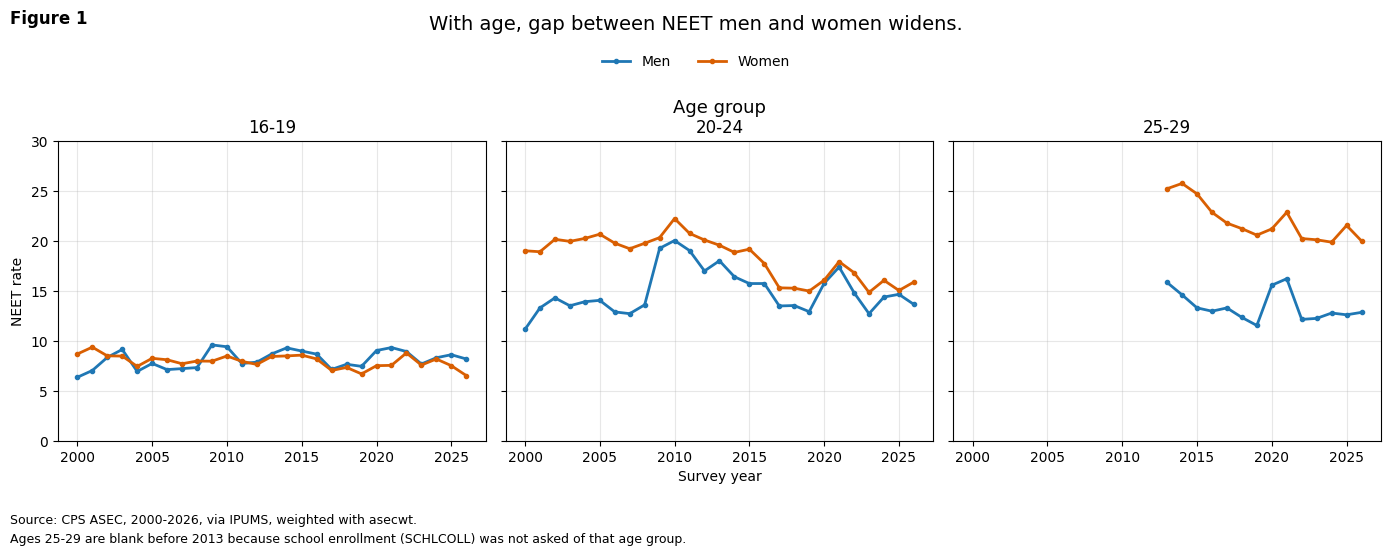

In [7]:
print("Table 1. NEET rate (%), weighted with asecwt. Rows: survey year. Figure 1 shows this table.")  # table title
print(rate.to_string(float_format="{:.1f}".format, na_rep=""))  # table, 1 decimal, blanks stay blank

age_groups = ["16-19", "20-24", "25-29"]  # one panel per age group
colors = {"Men": "#1f77b4", "Women": "#d95f02"}  # same color for each sex in every panel
first_year = int(rate.index.min())  # first year in the table
last_year = int(rate.index.max())  # last year in the table
ymax = int(np.floor(rate.max().max() / 5) * 5 + 5)  # round number just above the highest value

last_row = rate.loc[last_year]  # NEET rates in the last year
best = last_row.idxmax()  # (age group, sex) with the highest rate that year
title = "With age, gap between NEET men and women widens."  # finding, taken from the table

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5), sharex=True, sharey=True)  # three panels, same x and y axes
for ax, age in zip(axes, age_groups):  # one panel per age group
    for sex in ["Men", "Women"]:  # one line per sex
        ax.plot(rate.index, rate[(age, sex)], color=colors[sex], marker="o", markersize=3, linewidth=2, label=sex)  # blank years are not drawn
    ax.set_title(age)  # panel title is the age group
    ax.set_ylim(0, ymax)  # y-axis starts at 0 in every panel
    ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5 points, starting at 0
    ax.set_xticks(range(first_year, last_year + 1, 5))  # x ticks every 5 years
    ax.grid(True, alpha=0.3)  # light grid
axes[0].set_ylabel("NEET rate")  # y-axis label (shared by all panels)
axes[1].set_xlabel("Survey year")  # one x-axis label, centered under the middle panel (20-24)

handles, labels = axes[0].get_legend_handles_labels()  # Men and Women lines
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=2, frameon=False)  # one legend for all panels
fig.suptitle(title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 1", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.1, 1, 0.88])  # leave room for the title, legend, heading and notes
middle = axes[1].get_position()  # position of the middle panel (20-24)
fig.text((middle.x0 + middle.x1) / 2, middle.y1 + 0.045, "Age group", ha="center", va="bottom", fontsize=13)  # one heading, centered over the middle panel
fig.text(0.01, 0.055, f"Source: CPS ASEC, {first_year}-{last_year}, via IPUMS, weighted with asecwt.", fontsize=9)  # source note
fig.text(0.01, 0.02, "Ages 25-29 are blank before 2013 because school enrollment (SCHLCOLL) was not asked of that age group.", fontsize=9)  # required note
fig.savefig(fig_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding:

## Table 2: 2026 NEET rates by age group and sex

In [8]:
age_groups = ["16-19", "20-24", "25-29"]  # age groups, in order
row_order = [(age, sex) for age in age_groups for sex in ["Men", "Women"]]  # the six rows: Men before Women in each age group

age_vars = {"16-19": "age16_19", "20-24": "age20_24", "25-29": "age25_29"}  # age-group dummies from the cleaned data
sex_values = {"Men": 0, "Women": 1}  # female = 0 for Men, 1 for Women

def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

df26 = df[df["year"] == 2026].copy()  # keep only the 2026 survey
known = df26.dropna(subset=["neet"])  # keep only people whose neet is known

rows = {}  # weighted rates, one row per age group and sex
counts = {}  # unweighted respondents, one per row
for age, sex in row_order:  # loop over the six rows
    group = known[(known[age_vars[age]] == 1) & (known["female"] == sex_values[sex])]  # people in this row
    rows[f"{age} {sex}"] = {  # row label, e.g. "16-19 Men"
        "Unemployed NEET (%)": wmean(group, "unemployed_neet") * 100,  # weighted percent unemployed NEET
        "Out-of-labor-force NEET (%)": wmean(group, "nilf_neet") * 100,  # weighted percent out-of-labor-force NEET
        "Total NEET (%)": wmean(group, "neet") * 100,  # weighted percent NEET
    }  # end of one row
    counts[f"{age} {sex}"] = len(group)  # unweighted respondents in this row

table = pd.DataFrame(rows).T  # dictionary -> table, one row per age group and sex
people = pd.Series(counts)  # unweighted respondents, same row labels

gap = (table["Unemployed NEET (%)"] + table["Out-of-labor-force NEET (%)"] - table["Total NEET (%)"]).abs()  # difference in each row, before rounding
print("Table 2. NEET rates in 2026, % of people (weighted with asecwt). Rows: age group and sex.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal
print()  # empty line
print("Check: unemployed NEET + out-of-labor-force NEET = total NEET in every row:", bool((gap < 1e-9).all()))  # True or False
print("Largest difference in any row (before rounding):", gap.max())  # should be about 0
print()  # empty line
print("Unweighted number of respondents in each row (neet not missing).")  # counts title
print(people.to_string())  # counts, whole numbers

Table 2. NEET rates in 2026, % of people (weighted with asecwt). Rows: age group and sex.
             Unemployed NEET (%)  Out-of-labor-force NEET (%)  Total NEET (%)
16-19 Men                    2.3                          5.9             8.2
16-19 Women                  1.5                          5.0             6.5
20-24 Men                    5.0                          8.7            13.7
20-24 Women                  3.5                         12.4            15.9
25-29 Men                    5.2                          7.7            12.9
25-29 Women                  3.2                         16.9            20.0

Check: unemployed NEET + out-of-labor-force NEET = total NEET in every row: True
Largest difference in any row (before rounding): 1.7763568394002505e-15

Unweighted number of respondents in each row (neet not missing).
16-19 Men      3835
16-19 Women    3575
20-24 Men      3513
20-24 Women    3400
25-29 Men      3630
25-29 Women    3709


**What one cell means.** Take the row "20-24 Women" and the column "Unemployed NEET (%)". Among women aged 20-24 in the 2026 survey whose NEET status is known, the cell is the percent who were NEET and unemployed: not employed, looking for work, and not in school. The column "Out-of-labor-force NEET (%)" is the percent who were NEET and not looking for work. The column "Total NEET (%)" is the percent who were NEET, which is the first two columns added together. People are counted by how many people in the country they represent (`asecwt`), so each number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people. The counts under the table show how many survey respondents sit behind each row.

## Figure 2: 2026 NEET rates by age group and sex

Table 2. NEET rates in 2026, % of people (weighted with asecwt). Figure 2 shows this table.
             Unemployed NEET (%)  Out-of-labor-force NEET (%)  Total NEET (%)
16-19 Men                    2.3                          5.9             8.2
16-19 Women                  1.5                          5.0             6.5
20-24 Men                    5.0                          8.7            13.7
20-24 Women                  3.5                         12.4            15.9
25-29 Men                    5.2                          7.7            12.9
25-29 Women                  3.2                         16.9            20.0


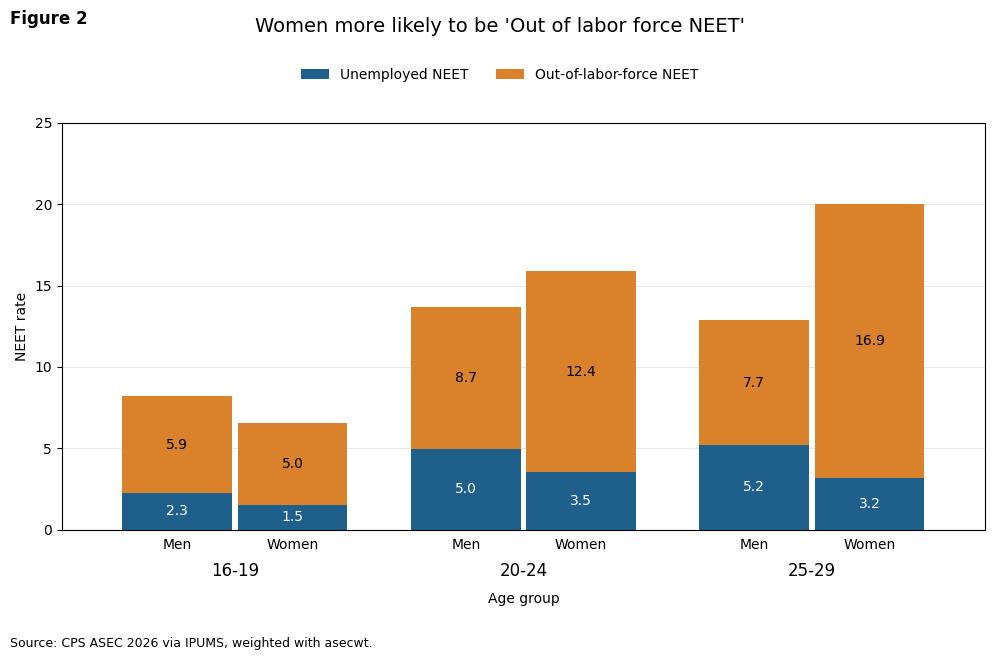

In [9]:
chart_title = "Women more likely to be 'Out of labor force NEET'"  # chart title: replace this text with your own sentence

print("Table 2. NEET rates in 2026, % of people (weighted with asecwt). Figure 2 shows this table.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal

age_groups = ["16-19", "20-24", "25-29"]  # one group of bars per age group
colors = ["#1f5f8b", "#d9822b"]  # unemployed NEET (bottom), out-of-labor-force NEET (top)
text_colors = ["white", "black"]  # number color inside each segment
ymax = int(table["Total NEET (%)"].max() / 5) * 5 + 5  # round number just above the tallest bar

fig, ax = plt.subplots(figsize=(10, 6.5))  # one chart
for g, age in enumerate(age_groups):  # loop over the three age groups
    for offset, sex in [(-0.2, "Men"), (0.2, "Women")]:  # Men first, then Women, side by side
        x = g + offset  # position of this bar
        row = table.loc[f"{age} {sex}"]  # numbers for this bar
        unemp = row["Unemployed NEET (%)"]  # bottom segment
        nilf = row["Out-of-labor-force NEET (%)"]  # top segment
        ax.bar(x, unemp, width=0.38, color=colors[0], label="Unemployed NEET" if g == 0 and sex == "Men" else None)  # bottom segment
        ax.bar(x, nilf, width=0.38, bottom=unemp, color=colors[1], label="Out-of-labor-force NEET" if g == 0 and sex == "Men" else None)  # top segment
        ax.text(x, unemp / 2, f"{unemp:.1f}", ha="center", va="center", color=text_colors[0], fontsize=10)  # value inside bottom segment
        ax.text(x, unemp + nilf / 2, f"{nilf:.1f}", ha="center", va="center", color=text_colors[1], fontsize=10)  # value inside top segment
        ax.text(x, -ymax * 0.02, sex, ha="center", va="top", fontsize=10)  # Men or Women under the bar
    ax.text(g, -ymax * 0.08, age, ha="center", va="top", fontsize=12)  # age group under its two bars

ax.set_xticks([])  # no default x ticks, the labels above are used instead
ax.set_xlim(-0.6, 2.6)  # room on both sides
ax.set_xlabel("Age group", labelpad=45)  # x-axis label, pushed below the age groups
ax.set_ylabel("NEET rate")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, axis="y", alpha=0.3)  # light grid behind the bars
ax.set_axisbelow(True)  # grid lines behind the bars

handles, labels = ax.get_legend_handles_labels()  # the two NEET types
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 2", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.05, 1, 0.9])  # leave room for the title, legend and note
fig.text(0.01, 0.01, "Source: CPS ASEC 2026 via IPUMS, weighted with asecwt.", fontsize=9)  # source note
fig.savefig(fig2_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding:

## Table 3: 2026 Education of NEET people by age group and sex

In [10]:
dummies = {"less_hs": "Less than high school", "hs_ged": "High school or GED", "some_college": "Some college", "bachelor_plus": "Bachelor or higher"}  # education dummies and their labels, in order
age_groups = ["16-19", "20-24", "25-29"]  # age groups, in order
row_order = [(age, sex) for age in age_groups for sex in ["Men", "Women"]]  # the six rows: Men before Women in each age group

age_vars = {"16-19": "age16_19", "20-24": "age20_24", "25-29": "age25_29"}  # age-group dummies from the cleaned data
sex_values = {"Men": 0, "Women": 1}  # female = 0 for Men, 1 for Women

neet26 = df[(df["year"] == 2026) & (df["neet"] == 1)].copy()  # keep only 2026 and only NEET people
n_left_out = neet26[list(dummies)].isna().any(axis=1).sum()  # NEET people with missing education
known = neet26.dropna(subset=list(dummies))  # leave them out

percent = {}  # weighted percent, one row per age group and sex
people = {}  # unweighted respondents, same layout
for age, sex in row_order:  # loop over the six rows
    group = known[(known[age_vars[age]] == 1) & (known["female"] == sex_values[sex])]  # NEET people in this row
    total_weight = group["asecwt"].sum()  # weighted number of NEET people in this row
    percent[f"{age} {sex}"] = {}  # start this row of the table
    people[f"{age} {sex}"] = {}  # start this row of the counts
    for var, label in dummies.items():  # loop over the four education dummies
        percent[f"{age} {sex}"][label] = (group[var] * group["asecwt"]).sum() / total_weight * 100  # weighted percent with this education
        people[f"{age} {sex}"][label] = int((group[var] == 1).sum())  # unweighted respondents with this education

table = pd.DataFrame(percent).T  # dictionary -> table, one row per age group and sex
people = pd.DataFrame(people).T  # same layout for the counts

shown = table.copy().astype(object)  # text version of the table, for the asterisks
for row in table.index:  # loop over the rows
    for column in table.columns:  # loop over the columns
        star = "*" if people.loc[row, column] < 30 else " "  # asterisk if fewer than 30 respondents
        shown.loc[row, column] = f"{table.loc[row, column]:.1f}{star}"  # percent with 1 decimal, then the asterisk or a space

row_sums = table.sum(axis=1)  # each row's total, before rounding
off = (row_sums - 100).abs()  # distance from 100 in each row

print("NEET people in 2026 left out because education is missing (unweighted):", n_left_out)  # how many were left out
print()  # empty line
print("Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt).")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks
print("* fewer than 30 unweighted respondents")  # key for the asterisk
print()  # empty line
print("Check: every row adds up to 100.0:", bool((off < 1e-9).all()))  # True or False
print("Largest distance from 100 in any row (before rounding):", off.max())  # should be about 0
print()  # empty line
print("Unweighted number of respondents in each cell.")  # counts title
print(people.to_string())  # counts, same layout

NEET people in 2026 left out because education is missing (unweighted): 0

Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt).
            Less than high school High school or GED Some college Bachelor or higher
16-19 Men                   39.0               54.9          5.8*               0.3*
16-19 Women                 42.2               45.5         12.1*               0.3*
20-24 Men                   21.0               56.4         15.4                7.2 
20-24 Women                 17.1               54.5         17.9               10.5 
25-29 Men                   12.8               46.4         22.9               17.9 
25-29 Women                 13.0               45.3         19.5               22.2 
* fewer than 30 unweighted respondents

Check: every row adds up to 100.0: True
Largest distance from 100 in any row (before rounding): 2.842170943040401e-14

Unweighted number of respondents in each cell.
             Less than high 

**What one cell means.** Take the row "20-24 Women" and the column "Some college". Among women aged 20-24 in the 2026 survey who were NEET (not employed and not in school) and whose education is known, the cell is the percent who had some college. Each row adds up to 100, so the cells show how NEET people in that row are split across the four education levels. This is a share of NEET people, not a share of all women aged 20-24, so it is not a NEET rate. People are counted by how many people in the country they represent (`asecwt`). An asterisk marks a cell with fewer than 30 survey respondents behind it, shown in the count table under the table.

## Figure 3: Education of NEET people by age group and sex, 2026

Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt). Figure 3 shows this table.
            Less than high school High school or GED Some college Bachelor or higher
16-19 Men                   39.0               54.9          5.8*               0.3*
16-19 Women                 42.2               45.5         12.1*               0.3*
20-24 Men                   21.0               56.4         15.4                7.2 
20-24 Women                 17.1               54.5         17.9               10.5 
25-29 Men                   12.8               46.4         22.9               17.9 
25-29 Women                 13.0               45.3         19.5               22.2 
* fewer than 30 unweighted respondents


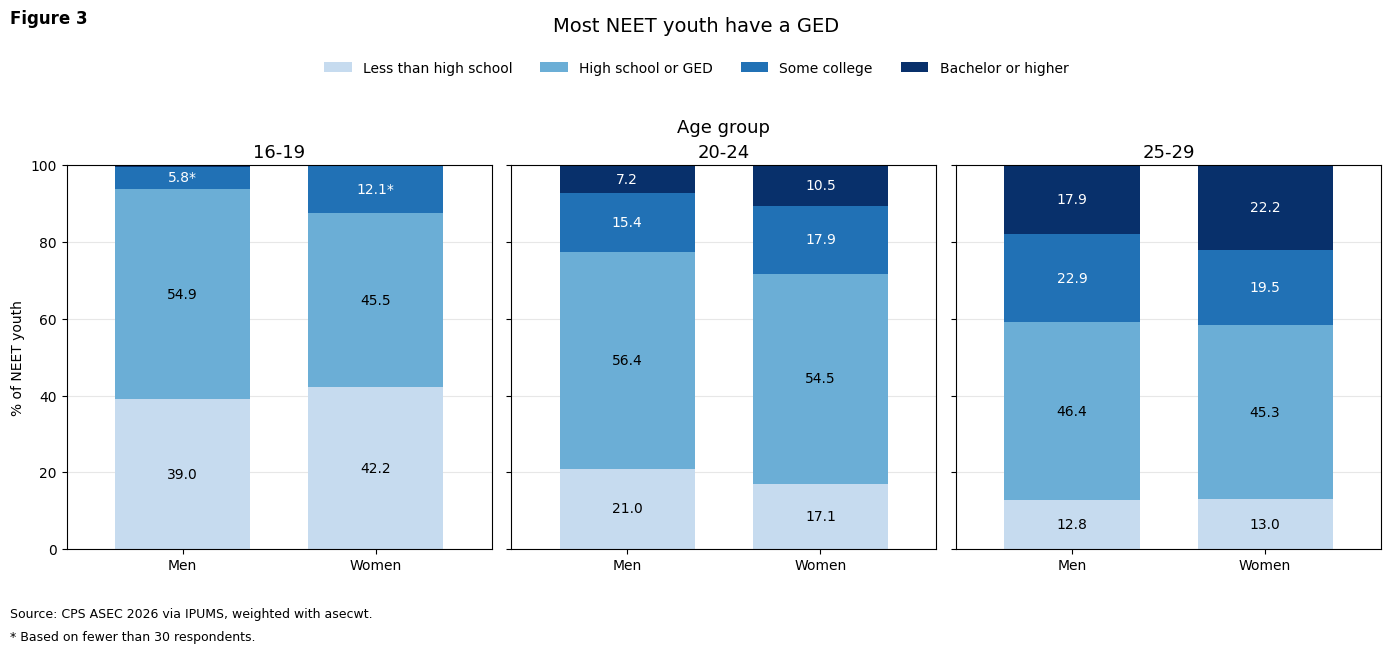

In [11]:
chart_title = "Most NEET youth have a GED"  # chart title: replace this text with your own sentence

print("Table 3. Education of NEET people in 2026, % of NEET people in each row (weighted with asecwt). Figure 3 shows this table.")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks
print("* fewer than 30 unweighted respondents")  # key for the asterisk

colors = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]  # four shades of blue, light = lowest education, dark = highest
text_colors = ["black", "black", "white", "white"]  # number color inside each segment
asterisk_shown = False  # becomes True if any shown label gets an asterisk

fig, axes = plt.subplots(1, 3, figsize=(14, 6.5), sharey=True)  # three panels, same y-axis
for ax, age in zip(axes, age_groups):  # one panel per age group
    for x, sex in enumerate(["Men", "Women"]):  # Men first, then Women, next to each other
        row = f"{age} {sex}"  # row label in the table
        bottom = 0  # where the next segment starts
        for i, column in enumerate(table.columns):  # stack from the lowest education level to the highest
            value = table.loc[row, column]  # percent for this segment
            ax.bar(x, value, bottom=bottom, width=0.7, color=colors[i], label=column if (age == age_groups[0] and sex == "Men") else None)  # one segment
            if value >= 3.0:  # label only segments of 3.0% or more
                star = "*" if people.loc[row, column] < 30 else ""  # asterisk if fewer than 30 respondents
                asterisk_shown = asterisk_shown or star == "*"  # remember that an asterisk is on the chart
                ax.text(x, bottom + value / 2, f"{value:.1f}{star}", ha="center", va="center", color=text_colors[i], fontsize=10)  # value inside the segment
            bottom = bottom + value  # next segment starts on top of this one
    ax.set_title(age, fontsize=13)  # panel title is the age group
    ax.set_xticks([0, 1])  # one tick under each bar
    ax.set_xticklabels(["Men", "Women"])  # Men and Women under each bar
    ax.set_xlim(-0.6, 1.6)  # room on both sides
    ax.set_ylim(0, 100)  # y-axis from 0 to 100
    ax.set_yticks(range(0, 101, 20))  # y ticks every 20
    ax.grid(True, axis="y", alpha=0.3)  # light grid behind the bars
    ax.set_axisbelow(True)  # grid lines behind the bars
axes[0].set_ylabel("% of NEET youth")  # y-axis label (shared by all panels)

handles, labels = axes[0].get_legend_handles_labels()  # the four education levels
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=4, frameon=False)  # one legend for all panels
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 3", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.1, 1, 0.86])  # leave room for the title, legend, heading and notes
middle = axes[1].get_position()  # position of the middle panel (20-24)
fig.text((middle.x0 + middle.x1) / 2, middle.y1 + 0.045, "Age group", ha="center", va="bottom", fontsize=13)  # one heading, centered over the middle panel
fig.text(0.01, 0.055, "Source: CPS ASEC 2026 via IPUMS, weighted with asecwt.", fontsize=9)  # source note
if asterisk_shown:  # only if an asterisk appears on the chart
    fig.text(0.01, 0.02, "* Based on fewer than 30 respondents.", fontsize=9)  # required note
fig.savefig(fig3_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding:

## Table 4: 2026 NEET status by poverty status

In [12]:
from IPython.display import display  # shows the shaded table

row_values = {"NEET": 1, "Not NEET": 0}  # rows: neet = 1 is NEET, neet = 0 is not NEET
column_values = {"Poor": 1, "Not poor": 0}  # columns: poor = 1 is poor, poor = 0 is not poor

year26 = df[df["year"] == 2026]  # keep only the 2026 survey
known = year26.dropna(subset=["neet", "poor"])  # leave out people with neet or poor missing
n_left_out = len(year26) - len(known)  # how many were left out

percent = {}  # weighted percent, one row per NEET status
people = {}  # unweighted respondents, same layout
for row_label, neet_value in row_values.items():  # loop over NEET and Not NEET
    group = known[known["neet"] == neet_value]  # people in this row
    total_weight = group["asecwt"].sum()  # weighted number of people in this row
    percent[row_label] = {}  # start this row of the table
    people[row_label] = {}  # start this row of the counts
    for column_label, poor_value in column_values.items():  # loop over Poor and Not poor
        cell = group[group["poor"] == poor_value]  # people in this cell
        percent[row_label][column_label] = cell["asecwt"].sum() / total_weight * 100  # weighted percent of the row
        people[row_label][column_label] = len(cell)  # unweighted respondents in this cell

table = pd.DataFrame(percent).T  # dictionary -> table, one row per NEET status
people = pd.DataFrame(people).T  # same layout for the counts
off = (table.sum(axis=1) - 100).abs()  # distance from 100 in each row, before rounding

print("People in 2026 left out because neet or poor is missing (unweighted):", n_left_out)  # how many were left out
print()  # empty line
print("Table 4. NEET status by poverty status, 2026, % of people in each row (weighted with asecwt).")  # table title
display(table.style.background_gradient(cmap="Blues", axis=None).format("{:.1f}"))  # shaded table: darker blue = higher percent, 1 decimal
print()  # empty line
print("Check: every row adds up to 100.0:", bool((off < 1e-9).all()))  # True or False
print()  # empty line
print("Unweighted number of respondents in each cell.")  # counts title
print(people.to_string())  # counts, same layout

People in 2026 left out because neet or poor is missing (unweighted): 137

Table 4. NEET status by poverty status, 2026, % of people in each row (weighted with asecwt).


,Poor,Not poor
NEET,29.5,70.5
Not NEET,13.0,87.0



Check: every row adds up to 100.0: True

Unweighted number of respondents in each cell.
          Poor  Not poor
NEET       818      2010
Not NEET  2347     16487


## Write-up (50-100 words)

Question:

Finding:

## Table 5: 2026 Poverty rate by race and Hispanic origin and NEET status

In [13]:
race_rows = {"White, non-Hispanic": "white", "Black, non-Hispanic": "black", "Asian, non-Hispanic": "asian", "Hispanic (any race)": "hispanic", "Other, non-Hispanic": "other_race"}  # row labels and their race dummies, in order

def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

year26 = df[df["year"] == 2026]  # keep only the 2026 survey

race_count = year26[list(race_rows.values())].sum(axis=1)  # number of race dummies equal to 1, for each person
n_not_one = (race_count != 1).sum()  # people without exactly one race dummy equal to 1
print("Check: every person in 2026 has exactly one race dummy equal to 1:", bool(n_not_one == 0))  # True or False
print("People without exactly one race dummy equal to 1:", n_not_one)  # should be 0

label_for = df.dropna(subset=["neet", "neet_label"]).drop_duplicates("neet").set_index("neet")["neet_label"]  # neet_label for each value of neet
groups = [(1, label_for[1]), (0, label_for[0])]  # (neet value, column name): NEET first, then Not NEET

known = year26.dropna(subset=["poor", "neet"])  # leave out people with poor or neet missing
print("People in 2026 left out because poor or neet is missing (unweighted):", len(year26) - len(known))  # how many were left out
print()  # empty line

rate = {}  # weighted poverty rate, one row per race group
people = {}  # unweighted respondents, same layout
for race_label, race_var in race_rows.items():  # loop over the five race groups
    rate[race_label] = {}  # start this row of the table
    people[race_label] = {}  # start this row of the counts
    for neet_value, column_name in groups:  # loop over NEET and Not NEET
        cell = known[(known[race_var] == 1) & (known["neet"] == neet_value)]  # people in this cell
        rate[race_label][column_name] = wmean(cell, "poor") * 100  # weighted percent poor
        people[race_label][column_name] = len(cell)  # unweighted respondents in this cell

table = pd.DataFrame(rate).T  # dictionary -> table, one row per race group
people = pd.DataFrame(people).T  # same layout for the counts

shown = table.copy().astype(object)  # text version of the table, for the asterisks
for row in table.index:  # loop over the rows
    for column_name in people.columns:  # loop over the NEET and Not NEET columns
        is_small = people.loc[row, column_name] < 30  # fewer than 30 unweighted respondents
        shown.loc[row, column_name] = f"{table.loc[row, column_name]:.1f}" + ("*" if is_small else " ")  # percent, then an asterisk or a space

print("Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents.")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks
print()  # empty line
print("Unweighted number of respondents in each cell.")  # counts title
print(people.to_string())  # counts, same layout
print()  # empty line
print("Poverty status is based on 2025 income; NEET status refers to the March 2026 survey week. Poverty is measured for the whole household, not the individual.")  # required note

Check: every person in 2026 has exactly one race dummy equal to 1: True
People without exactly one race dummy equal to 1: 0
People in 2026 left out because poor or neet is missing (unweighted): 137

Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents.
                      NEET Not NEET
White, non-Hispanic  23.6      9.3 
Black, non-Hispanic  36.5     15.9 
Asian, non-Hispanic  28.9     16.9 
Hispanic (any race)  35.8     18.1 
Other, non-Hispanic  26.2      9.8 

Unweighted number of respondents in each cell.
                     NEET  Not NEET
White, non-Hispanic  1292      9312
Black, non-Hispanic   397      1903
Asian, non-Hispanic   139      1412
Hispanic (any race)   817      5177
Other, non-Hispanic   183      1030

Poverty status is based on 2025 income; NEET status refers to the March 2026 survey week. Poverty is measured for the whole household, not the individual.


**What one cell means.** Take the row "Hispanic (any race)" and the column "NEET". Among Hispanic people in the 2026 survey who were NEET (not employed and not in school) and whose poverty status is known, the cell is the percent who were poor, by the Supplemental Poverty Measure. The column "Not NEET" is the same percent for Hispanic people who were not NEET. People are counted by how many people in the country they represent (`asecwt`). Poverty is measured for the whole household, not the individual. An asterisk marks a cell with fewer than 30 survey respondents behind it. The count table under the table shows the number of respondents in each cell.

## Figure 4: Poverty rate by race and Hispanic origin and NEET status, 2026

Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents. Figure 4 shows this table.
                      NEET Not NEET
White, non-Hispanic  23.6      9.3 
Black, non-Hispanic  36.5     15.9 
Asian, non-Hispanic  28.9     16.9 
Hispanic (any race)  35.8     18.1 
Other, non-Hispanic  26.2      9.8 


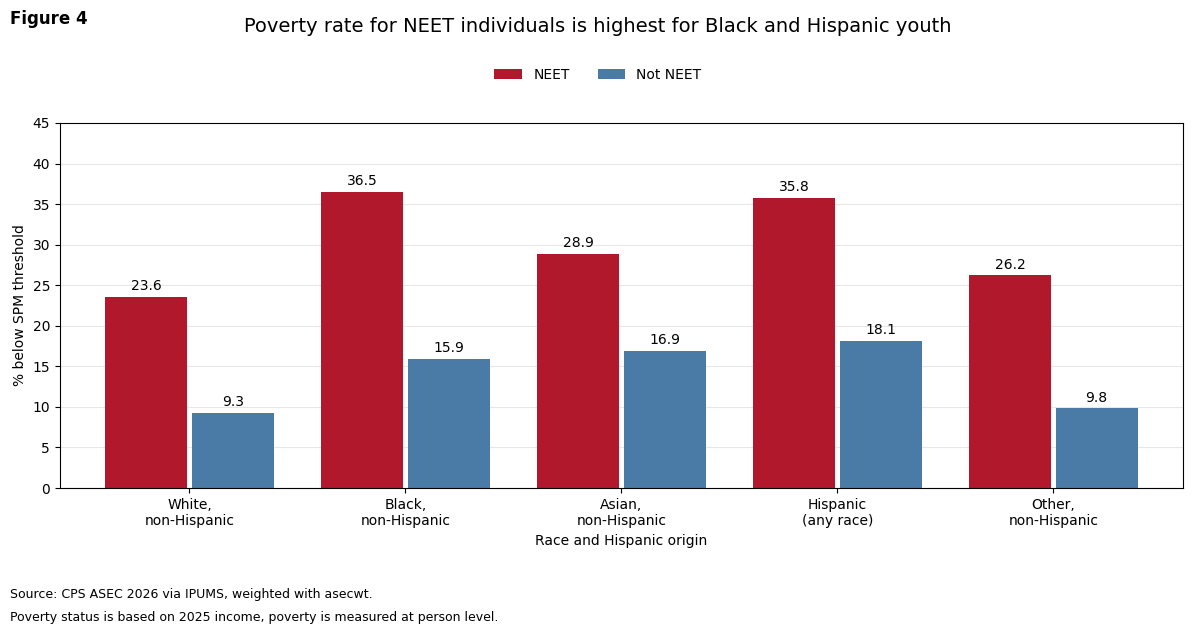

In [14]:
chart_title = "Poverty rate for NEET individuals is highest for Black and Hispanic youth"  # chart title: replace this text with your own sentence

print("Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents. Figure 4 shows this table.")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks

group_names = list(race_rows)  # the five race groups, in the same order as the table rows
bar_names = list(table.columns[:2])  # NEET first, then Not NEET
colors = ["#b2182b", "#4a7ba6"]  # one color for NEET, another for Not NEET
ymax = int(table[bar_names].max().max() * 1.15 / 5) * 5 + 5  # round number above the highest bar, with room for the labels
asterisk_shown = False  # becomes True if any bar label gets an asterisk

fig, ax = plt.subplots(figsize=(12, 6.5))  # one chart
for g, group_name in enumerate(group_names):  # loop over the five clusters
    for i, bar_name in enumerate(bar_names):  # NEET first, then Not NEET, next to each other
        x = g + (-0.2 if i == 0 else 0.2)  # position of this bar
        value = table.loc[group_name, bar_name]  # poverty rate for this bar
        star = "*" if people.loc[group_name, bar_name] < 30 else ""  # asterisk if fewer than 30 respondents
        asterisk_shown = asterisk_shown or star == "*"  # remember that an asterisk is on the chart
        ax.bar(x, value, width=0.38, color=colors[i], label=bar_name if g == 0 else None)  # the bar
        ax.text(x, value + ymax * 0.01, f"{value:.1f}{star}", ha="center", va="bottom", fontsize=10)  # value above the bar

ax.set_xticks(range(len(group_names)))  # one tick under each cluster
ax.set_xticklabels([textwrap.fill(name, width=12, break_on_hyphens=False) for name in group_names])  # group names on two lines
ax.set_xlim(-0.6, len(group_names) - 0.4)  # room on both sides
ax.set_xlabel("Race and Hispanic origin")  # x-axis label
ax.set_ylabel("% below SPM threshold")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, axis="y", alpha=0.3)  # light grid behind the bars
ax.set_axisbelow(True)  # grid lines behind the bars

handles, labels = ax.get_legend_handles_labels()  # NEET and Not NEET
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 4", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.14, 1, 0.9])  # leave room for the title, legend and notes
fig.text(0.01, 0.085, "Source: CPS ASEC 2026 via IPUMS, weighted with asecwt.", fontsize=9)  # source note
fig.text(0.01, 0.05, "Poverty status is based on 2025 income, poverty is measured at person level.", fontsize=9)  # required note
if asterisk_shown:  # only if an asterisk appears on the chart
    fig.text(0.01, 0.015, "* Based on fewer than 30 respondents.", fontsize=9)  # required note
fig.savefig(fig4_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding:

## Table 6: NEET rate by year and sex, ages 16 to 24, 2013 to 2026

In [15]:
def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

years = list(range(2013, 2027))  # the years in the table, 2013 to 2026
sample = df[df["year"].isin(years) & ((df["age16_19"] == 1) | (df["age20_24"] == 1))].copy()  # keep 2013 to 2026 and ages 16 to 24

label_for = df.drop_duplicates("female").set_index("female")["sex_label"]  # sex_label for each value of female
columns = {"Total": None, label_for[0]: 0, label_for[1]: 1}  # column names and the female value each one uses: Total, Male, Female

left_out = sample["neet"].isna().groupby(sample["year"]).sum()  # people left out in each year because neet is missing
known = sample.dropna(subset=["neet"])  # keep only people whose neet is known

rate = {}  # weighted NEET rate, one row per year
people = {}  # unweighted respondents, same layout
for year in years:  # loop over the years
    year_data = known[known["year"] == year]  # people in this year
    rate[year] = {}  # start this row of the table
    people[year] = {}  # start this row of the counts
    for column_name, female_value in columns.items():  # loop over Total, Male, Female
        group = year_data if female_value is None else year_data[year_data["female"] == female_value]  # everyone, or one sex
        rate[year][column_name] = wmean(group, "neet") * 100  # weighted percent NEET
        people[year][column_name] = len(group)  # unweighted respondents in this cell

table = pd.DataFrame(rate).T  # dictionary -> table, one row per year
people = pd.DataFrame(people).T  # same layout for the counts

print("People left out because neet is missing, by year (unweighted):")  # left-out title
print(left_out.to_string())  # one number per year
print()  # empty line
print("Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt).")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal
print()  # empty line
print("Check: every year from 2013 to 2026 is in the table:", list(table.index) == years)  # True or False
print("Check: every year has a value in all three columns:", bool(table.notna().all().all()))  # True or False
print()  # empty line
print("Unweighted number of respondents in each cell (neet not missing).")  # counts title
print(people.to_string())  # counts, same layout

People left out because neet is missing, by year (unweighted):
year
2013    111
2014    130
2015    135
2016    111
2017     90
2018    100
2019    107
2020     92
2021     94
2022     92
2023     83
2024     70
2025     75
2026     61

Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt).
      Total  Male  Female
2013   14.4  13.9    14.8
2014   13.9  13.3    14.4
2015   13.7  12.8    14.7
2016   13.1  12.7    13.6
2017   11.2  10.7    11.7
2018   11.4  10.9    11.8
2019   10.9  10.5    11.4
2020   12.5  12.7    12.3
2021   13.5  13.8    13.3
2022   12.7  12.2    13.3
2023   11.1  10.5    11.7
2024   12.1  11.6    12.5
2025   11.8  11.9    11.7
2026   11.5  11.2    11.8

Check: every year from 2013 to 2026 is in the table: True
Check: every year has a value in all three columns: True

Unweighted number of respondents in each cell (neet not missing).
      Total   Male  Female
2013  24160  12092   12068
2014  23429  11811   11618
2015  23225  11746   

**What one cell means.** Take the row 2019 and the column "Female". Among women aged 16 to 24 in the 2019 survey whose NEET status is known, the cell is the percent who were NEET: not employed and not in school. The column "Male" is the same percent for men, and the column "Total" is the same percent for men and women together. People whose NEET status could not be determined are left out, not counted as zero. People are counted by how many people in the country they represent (`asecwt`), so each number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people were NEET. The count table under the table shows how many survey respondents sit behind each cell.

## Figure 5: NEET rate by year and sex, ages 16 to 24, 2013 to 2026

Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt). Figure 5 shows this table.
      Total  Male  Female
2013   14.4  13.9    14.8
2014   13.9  13.3    14.4
2015   13.7  12.8    14.7
2016   13.1  12.7    13.6
2017   11.2  10.7    11.7
2018   11.4  10.9    11.8
2019   10.9  10.5    11.4
2020   12.5  12.7    12.3
2021   13.5  13.8    13.3
2022   12.7  12.2    13.3
2023   11.1  10.5    11.7
2024   12.1  11.6    12.5
2025   11.8  11.9    11.7
2026   11.5  11.2    11.8


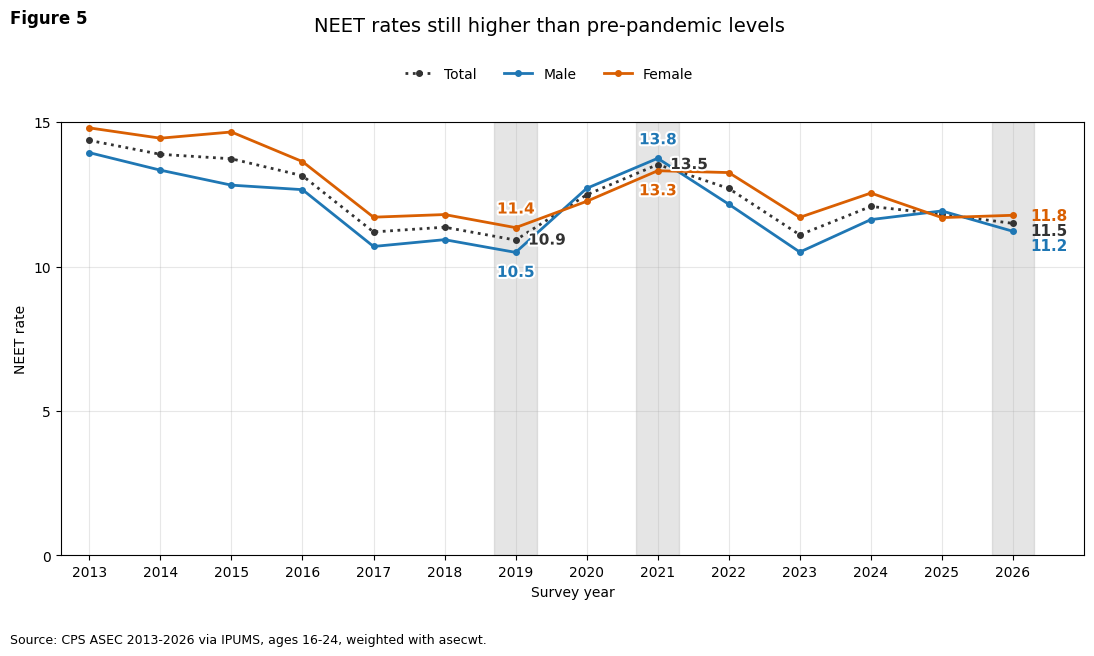

In [16]:
chart_title = "NEET rates still higher than pre-pandemic levels"  # chart title: replace this text with your own sentence

print("Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt). Figure 5 shows this table.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal

line_styles = {"Total": ":", table.columns[1]: "-", table.columns[2]: "-"}  # Total dotted, Male and Female solid
line_colors = {"Total": "#333333", table.columns[1]: "#1f77b4", table.columns[2]: "#d95f02"}  # a different color for each line
ymax = int(table.max().max() / 5) * 5 + 5  # round number just above the highest value in the table
last_year = table.index.max()  # the last year, 2026

fig, ax = plt.subplots(figsize=(11, 6.5))  # one chart
for year in [2019, 2021, last_year]:  # the three highlighted years
    ax.axvspan(year - 0.3, year + 0.3, color="gray", alpha=0.2, zorder=0)  # translucent grey column behind the lines
for column in table.columns:  # one line for each column: Total, Male, Female
    ax.plot(table.index, table[column], linestyle=line_styles[column], color=line_colors[column], marker="o", markersize=4, linewidth=2, label=column)  # line with a small marker on each point

end_values = table.loc[last_year].sort_values(ascending=False)  # last-year values, highest first
min_gap = ymax * 0.035  # smallest vertical space between two end labels
label_y = {}  # where each end label is written
previous = None  # height of the label above
for column, value in end_values.items():  # loop from the highest line to the lowest
    y = value if previous is None else min(value, previous - min_gap)  # move a label down if it would overlap the one above
    label_y[column] = y  # remember where it goes
    previous = y  # next label must sit below this one
for column, value in end_values.items():  # write the end labels
    ax.text(last_year + 0.25, label_y[column], f"{value:.1f}", color=line_colors[column], va="center", ha="left", fontsize=11, fontweight="bold")  # value of the last year at the end of the line

import matplotlib.patheffects as pe  # text outlines
total_name = table.columns[0]  # the Total column
sex_names = list(table.columns[1:])  # the Male and Female columns
for year in [2019, 2021]:  # years to label in the middle of the chart
    values = table.loc[year]  # the three values for this year
    top = values[sex_names].idxmax()  # the higher of Male and Female
    bottom = [name for name in sex_names if name != top][0]  # the other one, the lower
    outline = [pe.withStroke(linewidth=3, foreground="white")]  # thin white outline so the number is easy to read without hiding the lines
    ax.annotate(f"{values[top]:.1f}", (year, values[top]), xytext=(0, 8), textcoords="offset points", ha="center", va="bottom", color=line_colors[top], fontsize=11, fontweight="bold", path_effects=outline)  # higher line: value above the point
    ax.annotate(f"{values[bottom]:.1f}", (year, values[bottom]), xytext=(0, -9), textcoords="offset points", ha="center", va="top", color=line_colors[bottom], fontsize=11, fontweight="bold", path_effects=outline)  # lower line: value below the point
    ax.annotate(f"{values[total_name]:.1f}", (year, values[total_name]), xytext=(9, 0), textcoords="offset points", ha="left", va="center", color=line_colors[total_name], fontsize=11, fontweight="bold", path_effects=outline)  # Total line: value to the right of the point

ax.set_xticks(list(table.index))  # a tick for every year
ax.set_xlim(table.index.min() - 0.4, last_year + 1.0)  # room at the right for the end labels
ax.set_xlabel("Survey year")  # x-axis label
ax.set_ylabel("NEET rate")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, alpha=0.3)  # light grid

handles, labels = ax.get_legend_handles_labels()  # the three lines
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=3, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 5", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.06, 1, 0.9])  # leave room for the title, legend and note
fig.text(0.01, 0.015, "Source: CPS ASEC 2013-2026 via IPUMS, ages 16-24, weighted with asecwt.", fontsize=9)  # source note
fig.savefig(fig5_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding: